# 03 — Synthetic control: constructing a counterfactual for one treated unit

**Question B:** did California's Proposition 99 (a 25-cent cigarette excise tax, effective 1989)
reduce per-capita cigarette sales?

Everything that made notebook 02 work is unavailable here. There is one treated unit, so there is
no within-state control group to difference against, no cohort structure, and no way to estimate a
unit fixed effect that means anything. The comparison has to be *built*.

In [1]:
from pathlib import Path
import sys

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
FIGS = REPO / "report" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 25)

from cid import io as cidio, viz
from IPython.display import display, Image


def show(name, width=780):
    """Display a figure the analysis just wrote, so output is deterministic across backends."""
    path = FIGS / name
    if path.exists():
        display(Image(filename=str(path), embed=True, width=width))
    else:
        print("missing figure:", path)

In [2]:
from cid.sc import weights, placebo

smoking = cidio.load_smoking()
PRED = ["lnincome", "beer", "age15to24", "lnprice"]
smoking.pivot_table(index="year", columns="treated", values="cigsale", aggfunc="mean").round(1).head(3)

treated,0,1
year,,
1970,120.1,123.0
1971,123.9,121.0
1972,129.2,123.5


## 1. Three tempting answers, all wrong

Before building anything, run the naive analyses. Their failure is the argument for the method.

In [3]:
from cid.did import twfe

ca = smoking[smoking.state == "California"]
pre, post = ca[ca.year < 1989].cigsale.mean(), ca[ca.year >= 1989].cigsale.mean()
print("(a) California before/after only         : %+.2f packs" % (post - pre))

others = smoking[smoking.state != "California"]
pre_o, post_o = others[others.year < 1989].cigsale.mean(), others[others.year >= 1989].cigsale.mean()
print("(b) difference-in-means, no fixed effects: %+.2f packs" % ((post - pre) - (post_o - pre_o)))

naive_did = twfe.static_twfe(smoking, outcome="cigsale", id_col="state", g_col="g")
print("(c) two-way FE using all 38 controls     : %+.2f packs  (se %.2f)"
      % (naive_did["estimate"], naive_did["std_error"]))

(a) California before/after only         : -55.86 packs
(b) difference-in-means, no fixed effects: -27.35 packs
(c) two-way FE using all 38 controls     : -27.35 packs  (se 2.85)


(a) is confounded by everything that happened between 1970 and 2000 — national anti-smoking
norms, the 1984 federal excise increase, changing demographics. (b) additionally assumes the
average state resembles California, which the level difference alone refutes. (c) is the one a
careless analyst would publish: it treats all 38 states as a valid control group, weights
high- and low-consumption states alike, and gives *California's own pre-trend no role at all*.

(b) and (c) agree to the cent, which is not a coincidence: with one treated unit, no covariates and
a balanced panel, the two-way FE coefficient **is** the difference in mean changes, so running "the
regression version" of a crude comparison buys nothing. All three disagree with (a) by a factor of
two, and that gap is the national trend the before/after number mistakes for policy.

## 2. Building the synthetic California

Weights solve `min ||x_CA - X_donors' w||` over the simplex. Two feature constructions are
compared, and the choice is made on **pre-period fit**, not on which one supports the story.

In [4]:
F = weights.build_features(smoking, extra=PRED)
print("features used:", list(F.columns))
print("dropped for incompleteness:", F.attrs["dropped_incomplete"] or "none")
F.loc[["California", "Utah", "Montana", "Nevada", "Ohio", "Vermont"]].round(2)

features used: ['lnincome', 'beer', 'age15to24', 'lnprice', 'cigsale_mean', 'cigsale_slope']
dropped for incompleteness: none


,lnincome,beer,age15to24,lnprice,cigsale_mean,cigsale_slope
California,10.03,24.28,0.18,4.13,116.21,-1.78
Utah,9.66,13.34,0.20,4.07,71.48,-0.48
Montana,9.75,27.88,0.17,4.07,114.92,-1.40
Nevada,10.00,37.00,0.17,4.14,175.89,-3.81
Ohio,9.86,24.02,0.17,4.09,126.69,0.27
Vermont,9.76,27.06,0.18,4.09,148.49,-0.10


`cigsale_mean` and `cigsale_slope` are computed over the matching window, so a specification
that averages 1970-88 is matching a different California than one that averages 1980-88. This
matters, as the comparison below shows.

In [5]:
specs = {
    "features 1970-88": dict(predictors=PRED, feature_start=1970),
    "features 1980-88": dict(predictors=PRED, feature_start=1980),
    "features 1985-88": dict(predictors=PRED, feature_start=1985),
}
fits = {name: weights.fit(smoking, **kw) for name, kw in specs.items()}
fits["trajectory 1970-88"] = weights.trajectory_fit(smoking)

rows = []
for name, r in fits.items():
    rows.append(
        {
            "spec": name,
            "pre_rmspe": round(r["pre_rmspe"], 3),
            "post_rmspe": round(r["post_rmspe"], 3),
            "post/pre": round(r["rmspe_ratio"], 2),
            "effect_2000": round(r["final_year_effect"], 2),
            "mean_effect": round(r["mean_annual_effect"], 2),
            "active_donors": r["n_active_donors"],
        }
    )
pd.DataFrame(rows)

,spec,pre_rmspe,post_rmspe,post/pre,effect_2000,mean_effect,active_donors
0,features 1970-88,8.754,25.118,2.87,-32.07,-24.48,4
1,features 1980-88,5.995,22.082,3.68,-29.43,-21.19,4
2,features 1985-88,7.664,25.355,3.31,-32.89,-24.65,5
3,trajectory 1970-88,1.698,20.979,12.36,-26.90,-19.75,6


**Pre-period fit decides this.** The trajectory specification reproduces California's
consumption path to an RMSPE of about 1.7 packs on a base of roughly 116 — under 1.5% error. The
feature-based variants fit three to five times worse in the pre-period, which means their larger
post-period gaps are partly the residual of a bad match rather than the effect of the tax. Choosing
on fit is the only honest tie-break, and it is checked with placebos below.

Read the ratio column carefully before trusting it. The trajectory fit has the most extreme post/pre
ratio (12.4 against 2.9-3.7), which is partly arithmetic: a specification with a near-zero pre-period
RMSPE has a tiny denominator, so any post-period gap becomes a huge ratio. That is why the ratio is
reported next to the absolute pre-fit and never alone, and why the permutation test in section 4
filters donors on pre-fit before ranking them.

## 3. Who is the synthetic California?

In [6]:
best = fits["trajectory 1970-88"]
best["active_donors"].round(4).to_frame("weight")

,weight
Utah,0.3850
Montana,0.2715
Nevada,0.1854
Connecticut,0.0791
New Hampshire,0.0490
Colorado,0.0301


In [7]:
print("effective number of donors (1 / sum w^2): %.2f" % placebo.effective_donors(best["weights"]))
print("share carried by the top donor: %.0f%%" % (100 * best["weights"].max()))
print("share carried by the top three: %.0f%%" % (100 * best["weights"].nlargest(3).sum()))

effective number of donors (1 / sum w^2): 3.76
share carried by the top donor: 38%
share carried by the top three: 84%


This is the uncomfortable part of the result, and reporting it is the point. Six states carry
the counterfactual, the effective donor count is 3.76, and Utah, Montana and Nevada take 84% of the
weight between them. They are not a "low-consumption block" — Nevada averaged 176 packs against
California's 116 — so what the optimiser matched is the *shape* of the path, and Nevada's steep
1970-88 decline is close to California's. That is worth knowing: the weights can reward a donor with
the right slope and the wrong level, because the level gap is absorbed by the unit-sum constraint
rather than controlled by construction.

So the synthetic California is not a broad average of America. It is a small, deliberately chosen
mixture, and its credibility rests entirely on the pre-period fit tracking closely, not on how many
states are involved.

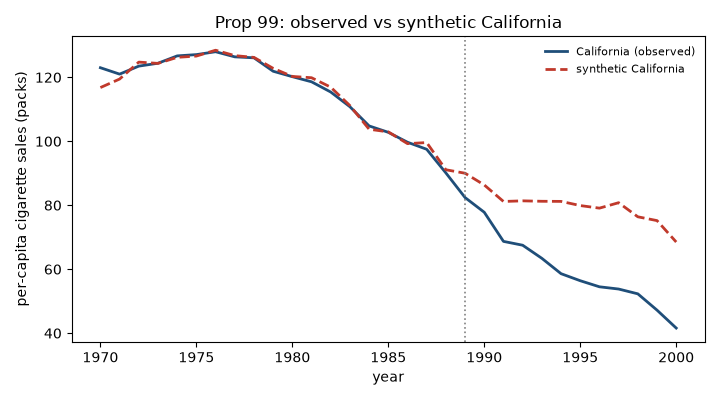

In [8]:
viz.sc_trajectories(best, "California", "Prop 99: observed vs synthetic California", path=FIGS / "fig3_sc.png")
show("fig3_sc.png")

Pre-1989 the two lines are nearly on top of each other, including the sharp decline through the
1980s. Post-1989 they separate and keep separating. A one-time shock would produce a level shift;
a price increase that permanently dampened consumption produces exactly this widening gap.

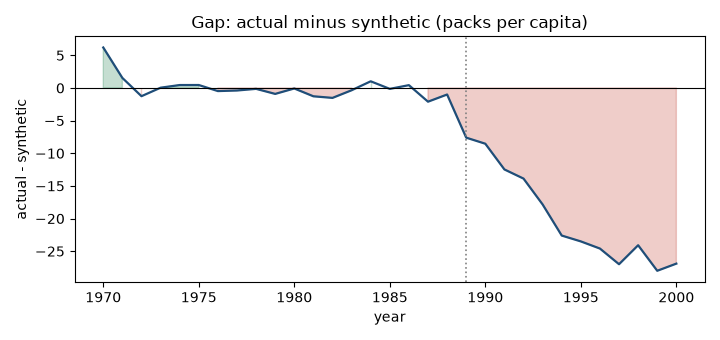

In [9]:
viz.sc_gap(best, "California", "Gap: actual minus synthetic (packs per capita)", path=FIGS / "fig4_gap.png")
show("fig4_gap.png")

In [10]:
print("cumulative 1989-2000 : %.1f packs per capita" % best["cumulative_effect"])
print("mean annual          : %.2f packs per capita" % best["mean_annual_effect"])
print("gap in final year    : %.2f packs per capita" % best["final_year_effect"])

cumulative 1989-2000 : -237.0 packs per capita
mean annual          : -19.75 packs per capita
gap in final year    : -26.90 packs per capita


## 4. Inference by permutation: in-space placebos

There is no sampling distribution for a single treated unit. The defensible substitute is to run
the identical procedure on every donor state as though *it* had been treated, with California
removed from the donor pool, and ask how extreme the real result looks. The metric is the post/pre
RMSPE ratio, which penalises placebos that fit badly to begin with.

In [11]:
pl = placebo.in_space(smoking, method="trajectory")
print("placebo runs            :", pl["n_placebo"])
print("California post/pre RMSPE ratio: %.2f" % pl["rmspe_ratio"])
print("p (all donors)                 : %.3f" % pl["p_value_all_donors"])
print("p (donors fitting at least as well): %.3f" % pl["p_value_pre_fit_filtered"])

placebo runs            : 38
California post/pre RMSPE ratio: 12.36
p (all donors)                 : 0.053
p (donors fitting at least as well): 0.167


In [12]:
pl["placebo"].head(10).round(2)

,unit,cumulative_effect,mean_annual_effect,pre_rmspe,post_rmspe,rmspe_ratio
16,Missouri,110.36,9.20,0.45,10.76,23.78
34,Virginia,-189.98,-15.83,0.84,16.50,19.75
5,Georgia,-113.42,-9.45,1.10,10.49,9.53
31,Texas,-170.51,-14.21,1.98,15.91,8.04
27,Rhode Island,-350.74,-29.23,3.85,30.49,7.91
25,Oklahoma,84.42,7.04,1.98,15.67,7.90
29,South Dakota,85.89,7.16,1.17,8.29,7.08
18,Nebraska,72.76,6.06,0.93,6.51,6.99
35,West Virginia,167.56,13.96,2.60,16.14,6.21
33,Vermont,-115.04,-9.59,2.62,15.57,5.94


In [13]:
ratio, n = pl["rmspe_ratio"], pl["n_placebo"]
p = pl["placebo"]
filt = p[p.pre_rmspe <= best["pre_rmspe"]]
beat = p.rmspe_ratio >= ratio
same_dir = beat & (p.mean_annual_effect < 0)
print("beats California, all donors        : %2d of %d -> p = %.3f" % (beat.sum(), n, beat.mean()))
print("beats California, filtered on fit   : %2d of %d -> p = %.3f"
      % (int((filt.rmspe_ratio >= ratio).sum()), len(filt), float((filt.rmspe_ratio >= ratio).mean())))
print("beats it AND in the same direction  : %2d of %d -> p = %.3f  (%s)"
      % (same_dir.sum(), n, same_dir.mean(), ", ".join(p[same_dir].unit)))
print("smallest attainable p with %d placebo units: %.3f" % (n, 1 / n))

beats California, all donors        :  2 of 38 -> p = 0.053
beats California, filtered on fit   :  2 of 12 -> p = 0.167
beats it AND in the same direction  :  1 of 38 -> p = 0.026  (Virginia)
smallest attainable p with 38 placebo units: 0.026


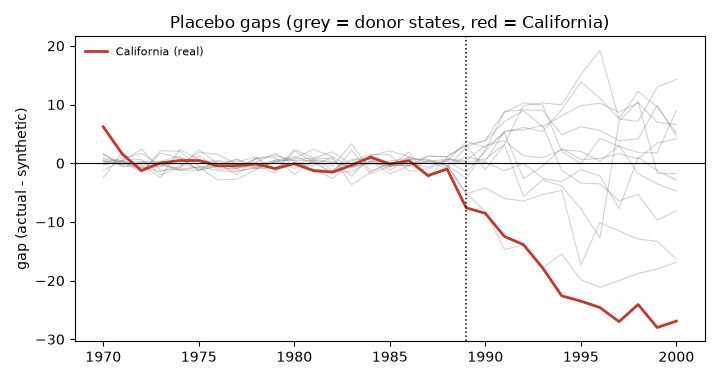

In [14]:
viz.placebo_overlay(pl["gap_curves"], best["gap"], best["pre_rmspe"], "California",
                    "Placebo gaps (grey = donor states, red = California)", path=FIGS / "fig5_placebo.png")
show("fig5_placebo.png")

Two numbers, and the second matters more than the first. Against all 38 donors the permutation
p is about 0.05: two placebos deteriorate more sharply post-treatment than California did. That is
close to the 1/39 floor, so it is roughly as strong as this design can ever look; anyone quoting a
smaller number from this dataset is using a different metric, not better evidence.

But one of those two is Missouri, whose pseudo-effect runs the *opposite* way (+9 packs a year).
Among the twelve donors that fit California at least as well in the pre-period, two exceed the ratio,
so the filtered p is **0.17 — not significant.** Counting only placebos that move in the same
direction as California leaves Virginia alone, 1 of 38.

That is the honest state of the inference here, and it is why the next section matters more than any
of these numbers. The case for Prop 99 rests on the *level* and persistence of a widening gap, on a
1.7-pack pre-period fit, and on a mechanism (a price increase, whose effect should grow with
duration) — not on a permutation test this design is too small to win.

## 5. In-time placebo: does the procedure invent effects before the tax?

The falsification test. Move the treatment date backwards and **truncate the sample at 1988** —
without truncation a 1984 pseudo-treatment has a post-window containing the real effect, and the
placebo "detects" Prop 99 itself, which looks like a refutation but is only a design error.

In [15]:
it = placebo.in_time(smoking, method="trajectory")
it.round(2)

,pseudo_treatment_year,mean_annual_effect,pre_rmspe,rmspe_ratio,n_post_periods
0,1978,-5.09,0.33,17.53,11
1,1981,-3.22,0.84,5.64,8
2,1984,-3.98,0.82,6.69,5
3,1987,-4.91,1.20,4.15,2


In [16]:
it_feat = placebo.in_time(smoking, predictors=PRED, feature_start=1980, method="features")
print("in-time placebo, feature-based specification:")
print(it_feat.round(2).to_string(index=False))
print()
print("mean pseudo-effect, trajectory : %+.2f packs/yr" % it.mean_annual_effect.mean())
print("mean pseudo-effect, features   : %+.2f packs/yr" % it_feat.mean_annual_effect.mean())

in-time placebo, feature-based specification:
 pseudo_treatment_year  mean_annual_effect  pre_rmspe  rmspe_ratio  n_post_periods
                  1981               -8.25       5.02         1.67               8
                  1984               -9.23       6.60         1.42               5
                  1987               -8.96       6.17         1.47               2

mean pseudo-effect, trajectory : -4.30 packs/yr
mean pseudo-effect, features   : -8.81 packs/yr


This is where the analysis gets interesting, and where a naive reproduction of the published
figure would have misled me. Pseudo-treatments in 1978-87 produce gaps of -3 to -5 packs per year,
not zero — an average of -4.3. The procedure does detect divergence before anything happened:
California's consumption was already falling faster than its synthetic counterpart.

Two consequences, reported rather than buried:

- The -19.75 mean annual effect is not fully attributable to the tax. About -4.3 packs a year is
  pre-existing differential trend, so roughly a fifth of the headline is not policy. The final-year
  gap (-26.9) is far larger than any single pseudo-effect, so the sign and the order of magnitude
  survive; the second decimal place does not.
- The feature-based specification manufactures pseudo-effects of -8 to -9, twice as large, which
  retroactively discredits its bigger headline numbers (-21 to -25 mean annual). Pre-period fit was
  already the tie-break in section 2; this is independent confirmation that it was the right one.

Note also that the pseudo-1978 run has a post/pre RMSPE ratio of 17.5, *larger* than the real 1989
run's 12.4. The ratio statistic alone would call 1978 the more significant event, and it was not an
event at all. Absolute gap size and persistence carry the information; the ratio is a ranking device.

The general lesson is the one synthetic control critics have pressed for years: a good pre-period fit
is necessary and not sufficient, and the in-time placebo is the test that separates the two. Here it
is visible in the output of a function I wrote rather than in a citation.

## 6. What to report

| Quantity | Value | Caveat |
|---|---|---|
| Gap, final year | -26.9 packs/capita | Includes some pre-existing differential trend |
| Mean annual gap 1989-2000 | -19.75 packs/capita | In-time placebos manufacture -4.3 of that from nothing |
| Pre-period RMSPE | 1.70 packs | The reason this specification was chosen |
| Permutation p, all donors | 0.053 | Floor is 1/39; one of the two "wins" has the wrong sign |
| Permutation p, well-fitting donors | 0.167 | The defensible number, and it is not significant |
| Effective donors | 3.76 | Utah + Montana + Nevada carry 84% of the weight |

Verdict: Prop 99 reduced California cigarette consumption. The direction and rough order of magnitude
hold across four specifications and 38 leave-one-donor-out refits (notebook 04). The *formal* evidence
is weaker than the published literature usually implies — restrict the permutation comparison to
donors that fit at least as well as California and p rises to 0.17 — and the in-time placebo shows a
genuine few packs per year of pre-existing divergence. The sign is safe, the magnitude is defensible,
and nobody who has run both placebos should quote the headline to two decimal places.